# 07 — Contexte écologique : prior géo-temporel
Sources : `results/geo_prior.csv`, `results/geo_fusion_<bb>.csv`, `results/geo_error_detection_<bb>.csv`, `results/geo_beta_*.json`.

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
R, F = ROOT / "results", ROOT / "figures"
pd.set_option("display.precision", 3); pd.set_option("display.width", 200)
def fig(name):
    p = F / f"{name}.png"
    display(Image(str(p))) if p.exists() else print("missing figure:", p.name)
def csv(name):
    p = R / name
    return pd.read_csv(p) if p.exists() else print("missing table:", p.name)

In [2]:
csv('geo_prior.csv')

,variant,n_train_rows,split,top1,top5,top10,nll
0,full,22906,S_val,0.170,0.492,0.690,3.075
1,full,22906,S_hold,0.188,0.454,0.662,3.131
2,full,22906,S_test,0.163,0.485,0.667,3.142
3,full,22906,A_hold,0.130,0.424,0.602,3.441
4,full,22906,A_test,0.145,0.403,0.615,3.389
5,full,22906,W_hold,0.148,0.408,0.610,3.427
6,full,22906,W_test,0.137,0.395,0.591,3.396
7,full,22906,P_hold,0.166,0.462,0.620,3.259
8,full,22906,P_test,0.150,0.437,0.619,3.243
9,blocked,9325,S_val,0.134,0.418,0.616,3.361


In [3]:
for bb in ['vit_s16', 'resnet50']:
    f = csv(f'geo_fusion_{bb}.csv')
    display(Markdown(f'**{bb}**'))
    display(f[f.condition=='clean'][['variant','beta','split','acc_visual','acc_fused','nll_visual','nll_fused','ece_visual','ece_fused']])
    e = csv(f'geo_error_detection_{bb}.csv'); e['kind'] = np.where(e.condition=='clean', 'clean', 'corrupted')
    display(e.groupby(['variant','kind'])[['error_rate','auroc_confidence','auroc_geo','auroc_combined']].mean())

**vit_s16**

,variant,beta,split,acc_visual,acc_fused,nll_visual,nll_fused,ece_visual,ece_fused
0,full,1.0,S_test,0.772,0.833,0.828,0.543,0.047,0.028
1,full,1.0,A_test,0.712,0.789,1.088,0.767,0.045,0.045
2,full,1.0,W_test,0.741,0.811,0.997,0.717,0.035,0.041
3,full,1.0,P_test,0.714,0.813,1.011,0.707,0.040,0.027
44,blocked,0.5,S_test,0.772,0.829,0.828,0.571,0.047,0.027
45,blocked,0.5,A_test,0.712,0.775,1.088,0.792,0.045,0.038
46,blocked,0.5,W_test,0.741,0.792,0.997,0.768,0.035,0.036
47,blocked,0.5,P_test,0.714,0.787,1.011,0.756,0.040,0.030


error_rate  auroc_confidence  auroc_geo  auroc_combined
variant kind                                                              
blocked clean           0.265             0.895      0.814           0.937
        corrupted       0.399             0.871      0.829           0.926
full    clean           0.265             0.895      0.844           0.941
        corrupted       0.399             0.871      0.856           0.932

**resnet50**

,variant,beta,split,acc_visual,acc_fused,nll_visual,nll_fused,ece_visual,ece_fused
0,full,0.50,S_test,0.492,0.640,2.086,1.357,0.065,0.046
1,full,0.50,A_test,0.446,0.572,2.263,1.578,0.042,0.048
2,full,0.50,W_test,0.453,0.592,2.228,1.559,0.045,0.047
3,full,0.50,P_test,0.457,0.596,2.220,1.537,0.035,0.039
44,blocked,0.75,S_test,0.492,0.601,2.086,1.431,0.065,0.063
45,blocked,0.75,A_test,0.446,0.534,2.263,1.685,0.042,0.058
46,blocked,0.75,W_test,0.453,0.576,2.228,1.663,0.045,0.035
47,blocked,0.75,P_test,0.457,0.566,2.220,1.624,0.035,0.062


error_rate  auroc_confidence  auroc_geo  auroc_combined
variant kind                                                              
blocked clean           0.538             0.799      0.836           0.893
        corrupted       0.774             0.746      0.861           0.869
full    clean           0.538             0.799      0.869           0.902
        corrupted       0.774             0.746      0.886           0.876

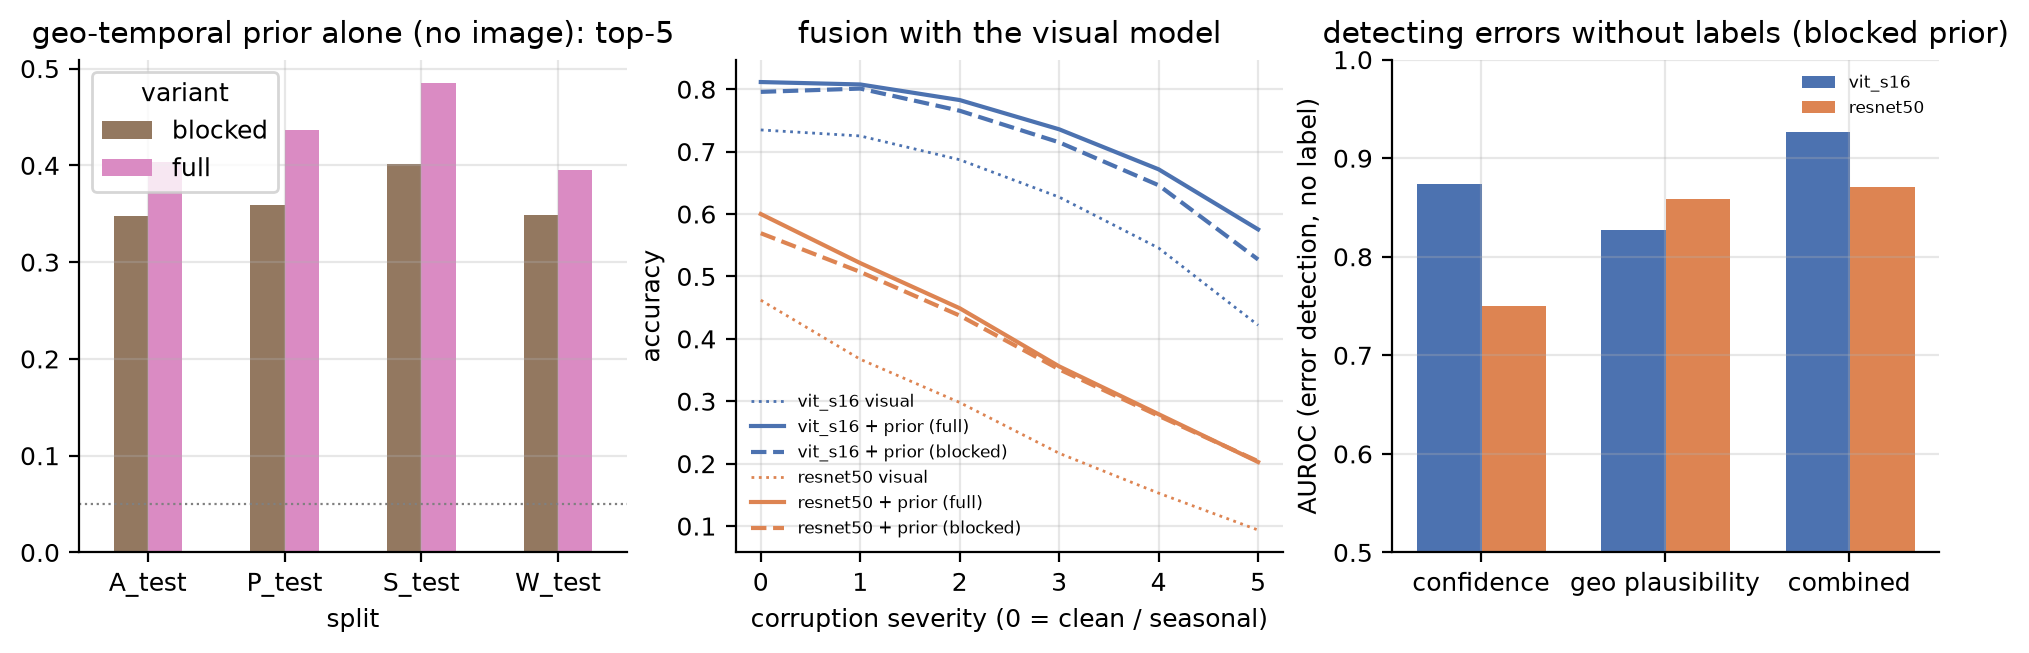

In [4]:
fig('08_geo_prior')